In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("UPI Payments Analytics Project")
print("Environment setup successful!")

Matplotlib is building the font cache; this may take a moment.


UPI Payments Analytics Project
Environment setup successful!


In [2]:
df = pd.read_csv(
    "../data/raw/indian_banking_transactions.csv"
)

print("Dataset loaded successfully!")
print("Shape:", df.shape)

display(df.head())

Dataset loaded successfully!
Shape: (550000, 20)


,transaction_id,customer_id,transaction_date,transaction_time,account_type,transaction_type,transaction_amount,transaction_direction,account_balance,merchant_category,state,credit_score,has_loan,loan_type,emi_amount,transaction_status,channel,kyc_status,is_fraud,transaction_hour
0,TXN000000001,CUST015796,2019-01-01,15:28,Current,UPI,1820.17,Debit,609365.31,Food & Dining,Maharashtra,764,0,NaN,0.00,Success,Branch,Verified,0,15
1,TXN000000002,CUST000861,2019-01-01,03:00,Current,UPI,392.67,Credit,14451.14,Education,West Bengal,630,0,NaN,0.00,Success,Mobile_App,Verified,0,3
2,TXN000000003,CUST076821,2019-01-01,18:03,Fixed Deposit,POS,1255.97,Debit,47621.87,Utilities,Punjab,813,1,Home,1433.91,Success,Mobile_App,Verified,0,18
3,TXN000000004,CUST054887,2019-01-01,08:03,Savings,UPI,2580.68,Debit,34467.85,Travel,Karnataka,628,1,Personal,6280.35,Success,API,Verified,0,8
4,TXN000000005,CUST006266,2019-01-01,14:23,Fixed Deposit,UPI,2573.80,Debit,26617.40,Utilities,West Bengal,767,0,NaN,0.00,Success,API,Verified,0,14


In [3]:
print(df.columns.tolist())

['transaction_id', 'customer_id', 'transaction_date', 'transaction_time', 'account_type', 'transaction_type', 'transaction_amount', 'transaction_direction', 'account_balance', 'merchant_category', 'state', 'credit_score', 'has_loan', 'loan_type', 'emi_amount', 'transaction_status', 'channel', 'kyc_status', 'is_fraud', 'transaction_hour']


In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 550000 entries, 0 to 549999
Data columns (total 20 columns):
 #   Column                 Non-Null Count   Dtype  
---  ------                 --------------   -----  
 0   transaction_id         550000 non-null  object 
 1   customer_id            550000 non-null  object 
 2   transaction_date       550000 non-null  object 
 3   transaction_time       550000 non-null  object 
 4   account_type           550000 non-null  object 
 5   transaction_type       550000 non-null  object 
 6   transaction_amount     550000 non-null  float64
 7   transaction_direction  550000 non-null  object 
 8   account_balance        550000 non-null  float64
 9   merchant_category      550000 non-null  object 
 10  state                  550000 non-null  object 
 11  credit_score           550000 non-null  int64  
 12  has_loan               550000 non-null  int64  
 13  loan_type              172866 non-null  object 
 14  emi_amount             550000 non-nu

In [5]:
df.isnull().sum()

transaction_id                0
customer_id                   0
transaction_date              0
transaction_time              0
account_type                  0
transaction_type              0
transaction_amount            0
transaction_direction         0
account_balance               0
merchant_category             0
state                         0
credit_score                  0
has_loan                      0
loan_type                377134
emi_amount                    0
transaction_status            0
channel                       0
kyc_status                    0
is_fraud                      0
transaction_hour              0
dtype: int64

In [6]:
df.duplicated().sum()

np.int64(0)

In [7]:
df.describe(include="all").T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
transaction_id,550000,550000,TXN000000001,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
customer_id,550000,79916,CUST003688,20,NaN,NaN,NaN,NaN,NaN,NaN,NaN
transaction_date,550000,1827,2023-11-11,373,NaN,NaN,NaN,NaN,NaN,NaN,NaN
transaction_time,550000,1440,06:25,448,NaN,NaN,NaN,NaN,NaN,NaN,NaN
account_type,550000,5,Savings,219651,NaN,NaN,NaN,NaN,NaN,NaN,NaN
transaction_type,550000,10,UPI,153986,NaN,NaN,NaN,NaN,NaN,NaN,NaN
transaction_amount,550000.0,NaN,NaN,NaN,29907.093934,139610.09652,2.4,763.0375,2035.735,8557.4975,10000000.0
transaction_direction,550000,2,Debit,370394,NaN,NaN,NaN,NaN,NaN,NaN,NaN
account_balance,550000.0,NaN,NaN,NaN,84550.115076,170914.586239,500.0,15157.785,36422.87,87607.035,5000000.0
merchant_category,550000,15,Retail,66180,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [8]:
df["transaction_type"].value_counts()

transaction_type
UPI               153986
IMPS               77038
NEFT               66615
POS                60278
ATM_Withdrawal     55106
Net_Banking        38458
RTGS               32964
Auto_Debit         27418
Cheque             21711
Credit_Card        16426
Name: count, dtype: int64

In [9]:
df["transaction_status"].value_counts()

transaction_status
Success     506247
Failed       21905
Reversed     11019
Pending      10829
Name: count, dtype: int64

In [10]:
df["is_fraud"].value_counts()

is_fraud
0    545127
1      4873
Name: count, dtype: int64

# 1. Data Quality Assessment

This section evaluates the quality and reliability of the UPI transactions dataset.

The assessment covers:
- Dataset dimensions
- Missing values
- Duplicate records
- Data types
- Unique values
- Data consistency

In [11]:
print("Total Rows:", df.shape[0])
print("Total Columns:", df.shape[1])
print("Total Records:", df.shape[0] * df.shape[1])

Total Rows: 550000
Total Columns: 20
Total Records: 11000000


In [12]:
missing = pd.DataFrame({
    "Missing_Count": df.isnull().sum(),
    "Missing_Percentage": (df.isnull().mean() * 100).round(2)
})

missing = missing.sort_values(
    by="Missing_Percentage",
    ascending=False
)

display(missing)

,Missing_Count,Missing_Percentage
loan_type,377134,68.57
transaction_id,0,0.00
customer_id,0,0.00
is_fraud,0,0.00
kyc_status,0,0.00
channel,0,0.00
transaction_status,0,0.00
emi_amount,0,0.00
has_loan,0,0.00
credit_score,0,0.00


In [13]:
print("Duplicate rows:", df.duplicated().sum())

if "transaction_id" in df.columns:
    print(
        "Duplicate transaction IDs:",
        df["transaction_id"].duplicated().sum()
    )

Duplicate rows: 0
Duplicate transaction IDs: 0


In [14]:
data_types = pd.DataFrame({
    "Column": df.columns,
    "Data_Type": df.dtypes.astype(str).values,
    "Unique_Values": df.nunique().values
})

display(data_types)

,Column,Data_Type,Unique_Values
0,transaction_id,object,550000
1,customer_id,object,79916
2,transaction_date,object,1827
3,transaction_time,object,1440
4,account_type,object,5
5,transaction_type,object,10
6,transaction_amount,float64,374552
7,transaction_direction,object,2
8,account_balance,float64,536170
9,merchant_category,object,15


In [15]:
numeric_cols = df.select_dtypes(
    include=np.number
).columns

outlier_summary = []

for col in numeric_cols:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)

    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    count = (
        (df[col] < lower) |
        (df[col] > upper)
    ).sum()

    outlier_summary.append({
        "Column": col,
        "Outlier_Count": count,
        "Outlier_Percentage": round(
            count / len(df) * 100, 2
        )
    })

display(pd.DataFrame(outlier_summary))

,Column,Outlier_Count,Outlier_Percentage
0,transaction_amount,88976,16.18
1,account_balance,53567,9.74
2,credit_score,0,0.00
3,has_loan,0,0.00
4,emi_amount,54281,9.87
5,is_fraud,4873,0.89
6,transaction_hour,0,0.00


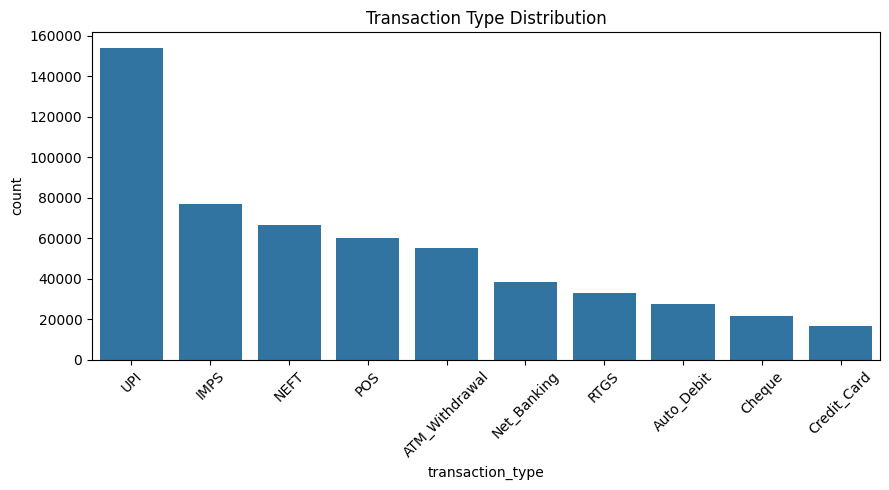

In [16]:
plt.figure(figsize=(9, 5))

sns.countplot(
    data=df,
    x="transaction_type",
    order=df["transaction_type"].value_counts().index
)

plt.title("Transaction Type Distribution")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

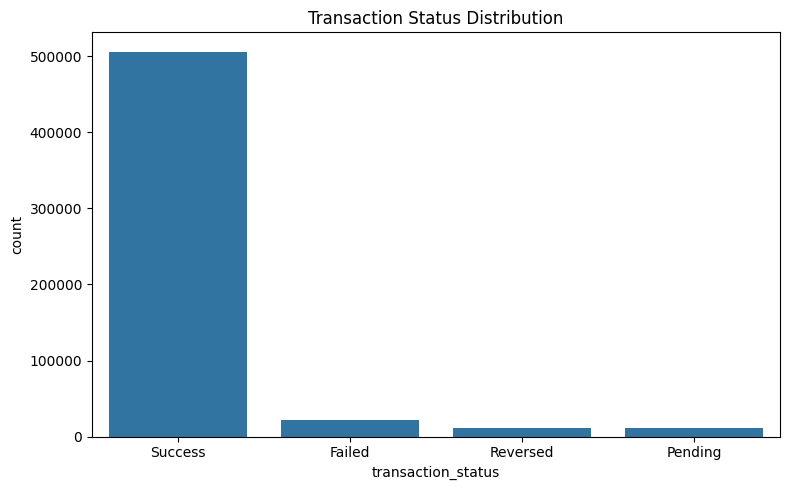

In [17]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x="transaction_status",
    order=df["transaction_status"].value_counts().index
)

plt.title("Transaction Status Distribution")
plt.tight_layout()
plt.show()

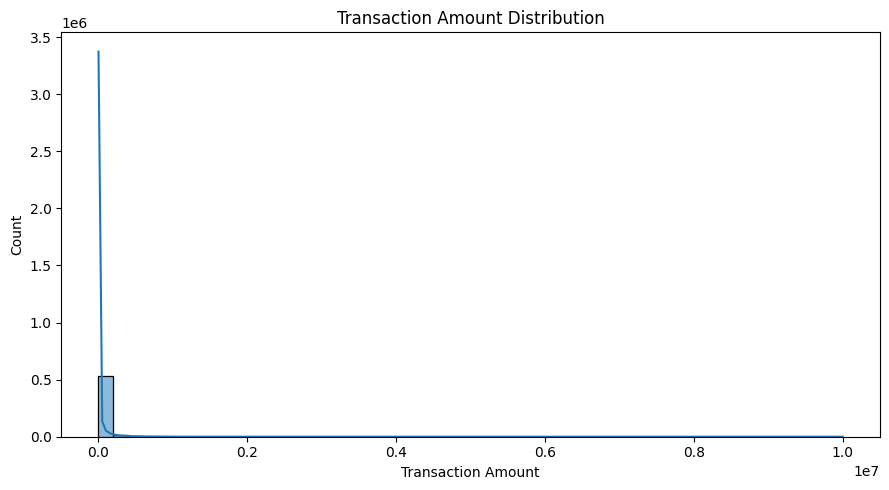

In [18]:
plt.figure(figsize=(9, 5))

sns.histplot(
    data=df,
    x="transaction_amount",
    bins=50,
    kde=True
)

plt.title("Transaction Amount Distribution")
plt.xlabel("Transaction Amount")
plt.tight_layout()
plt.show()

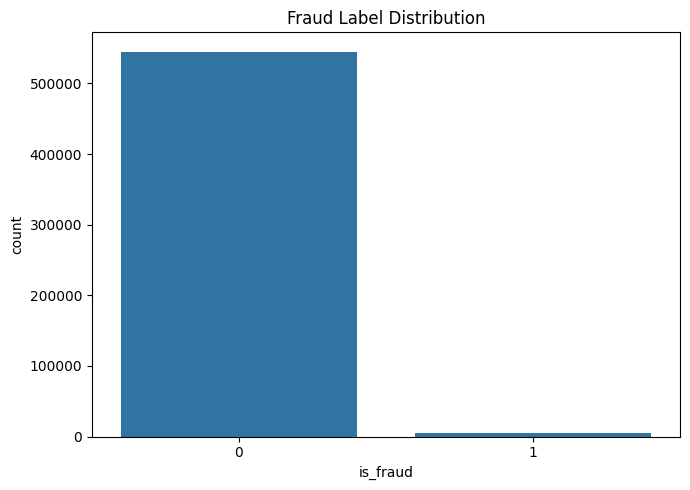

In [19]:
plt.figure(figsize=(7, 5))

sns.countplot(
    data=df,
    x="is_fraud"
)

plt.title("Fraud Label Distribution")
plt.tight_layout()
plt.show()

In [20]:
quality_report = pd.DataFrame({
    "Metric": [
        "Total Records",
        "Total Columns",
        "Duplicate Rows",
        "Missing Cells",
        "Unique Customers"
    ],
    "Value": [
        len(df),
        len(df.columns),
        df.duplicated().sum(),
        df.isnull().sum().sum(),
        df["customer_id"].nunique()
    ]
})

display(quality_report)

,Metric,Value
0,Total Records,550000
1,Total Columns,20
2,Duplicate Rows,0
3,Missing Cells,377134
4,Unique Customers,79916


In [22]:
quality_report.to_csv(
    "../reports/data_quality_summary.csv",
    index=False
)

## 2. Detailed Dataset Profiling

In [23]:
# Display all columns with their data types

for i, col in enumerate(df.columns, 1):
    print(f"{i}. {col} --> {df[col].dtype}")

1. transaction_id --> object
2. customer_id --> object
3. transaction_date --> object
4. transaction_time --> object
5. account_type --> object
6. transaction_type --> object
7. transaction_amount --> float64
8. transaction_direction --> object
9. account_balance --> float64
10. merchant_category --> object
11. state --> object
12. credit_score --> int64
13. has_loan --> int64
14. loan_type --> object
15. emi_amount --> float64
16. transaction_status --> object
17. channel --> object
18. kyc_status --> object
19. is_fraud --> int64
20. transaction_hour --> int64


In [24]:
missing_analysis = pd.DataFrame({
    "Column": df.columns,
    "Missing_Count": df.isnull().sum().values,
    "Missing_Percentage": (
        df.isnull().mean().values * 100
    ).round(2),
    "Unique_Values": df.nunique().values
})

missing_analysis = missing_analysis.sort_values(
    by="Missing_Percentage",
    ascending=False
)

display(missing_analysis)

,Column,Missing_Count,Missing_Percentage,Unique_Values
13,loan_type,377134,68.57,6
0,transaction_id,0,0.00,550000
1,customer_id,0,0.00,79916
18,is_fraud,0,0.00,2
17,kyc_status,0,0.00,3
16,channel,0,0.00,6
15,transaction_status,0,0.00,4
14,emi_amount,0,0.00,177524
12,has_loan,0,0.00,2
11,credit_score,0,0.00,600


In [25]:
print("Transaction date range:")
print(df["transaction_date"].min())
print(df["transaction_date"].max())

print("\nTransaction types:")
print(df["transaction_type"].value_counts(dropna=False))

print("\nTransaction statuses:")
print(df["transaction_status"].value_counts(dropna=False))

print("\nUnique customers:")
print(df["customer_id"].nunique())

print("\nUnique transactions:")
print(df["transaction_id"].nunique())

Transaction date range:
2019-01-01
2024-01-01

Transaction types:
transaction_type
UPI               153986
IMPS               77038
NEFT               66615
POS                60278
ATM_Withdrawal     55106
Net_Banking        38458
RTGS               32964
Auto_Debit         27418
Cheque             21711
Credit_Card        16426
Name: count, dtype: int64

Transaction statuses:
transaction_status
Success     506247
Failed       21905
Reversed     11019
Pending      10829
Name: count, dtype: int64

Unique customers:
79916

Unique transactions:
550000


## 3. Detailed Column Analysis

In [26]:
# Display all 20 columns without truncation

pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", None)
pd.set_option("display.width", 200)

column_profile = pd.DataFrame({
    "Column_Name": df.columns,
    "Data_Type": df.dtypes.astype(str).values,
    "Missing_Count": df.isnull().sum().values,
    "Missing_Percentage": (
        df.isnull().mean().values * 100
    ).round(2),
    "Unique_Values": df.nunique().values
})

display(column_profile)

,Column_Name,Data_Type,Missing_Count,Missing_Percentage,Unique_Values
0,transaction_id,object,0,0.00,550000
1,customer_id,object,0,0.00,79916
2,transaction_date,object,0,0.00,1827
3,transaction_time,object,0,0.00,1440
4,account_type,object,0,0.00,5
5,transaction_type,object,0,0.00,10
6,transaction_amount,float64,0,0.00,374552
7,transaction_direction,object,0,0.00,2
8,account_balance,float64,0,0.00,536170
9,merchant_category,object,0,0.00,15


In [27]:
missing_analysis = df.isnull().sum().reset_index()

missing_analysis.columns = [
    "Column",
    "Missing_Count"
]

missing_analysis["Missing_Percentage"] = (
    missing_analysis["Missing_Count"] / len(df) * 100
).round(2)

display(
    missing_analysis.sort_values(
        "Missing_Percentage",
        ascending=False
    )
)

,Column,Missing_Count,Missing_Percentage
13,loan_type,377134,68.57
0,transaction_id,0,0.00
1,customer_id,0,0.00
18,is_fraud,0,0.00
17,kyc_status,0,0.00
16,channel,0,0.00
15,transaction_status,0,0.00
14,emi_amount,0,0.00
12,has_loan,0,0.00
11,credit_score,0,0.00


In [28]:
df["transaction_date"] = pd.to_datetime(
    df["transaction_date"],
    errors="coerce"
)

print("Minimum date:", df["transaction_date"].min())
print("Maximum date:", df["transaction_date"].max())

print("\nRecords per year:")

display(
    df.groupby(
        df["transaction_date"].dt.year
    ).size().reset_index(name="Transaction_Count")
)

Minimum date: 2019-01-01 00:00:00
Maximum date: 2024-01-01 00:00:00

Records per year:


,transaction_date,Transaction_Count
0,2019,110083
1,2020,109767
2,2021,110024
3,2022,110247
4,2023,109584
5,2024,295


In [29]:
upi_df = df[
    df["transaction_type"].str.upper() == "UPI"
].copy()

print("Total UPI transactions:", len(upi_df))

print("\nUPI transaction statuses:")

display(
    upi_df["transaction_status"].value_counts()
)

print("\nUPI success rate:")

print(
    round(
        (upi_df["transaction_status"] == "Success").mean() * 100,
        2
    ),
    "%"
)

Total UPI transactions: 153986

UPI transaction statuses:


transaction_status
Success     141831
Failed        6096
Reversed      3054
Pending       3005
Name: count, dtype: int64


UPI success rate:
92.11 %


4. UPI Payment Performance Analysis


In [30]:
# Calculate UPI transaction KPIs

total = len(upi_df)

status_counts = upi_df["transaction_status"].value_counts()

success = status_counts.get("Success", 0)
failed = status_counts.get("Failed", 0)
reversed_txn = status_counts.get("Reversed", 0)
pending = status_counts.get("Pending", 0)

upi_kpis = pd.DataFrame({
    "Metric": [
        "Total Transactions",
        "Successful Transactions",
        "Failed Transactions",
        "Reversed Transactions",
        "Pending Transactions",
        "Success Rate",
        "Failure Rate",
        "Reversal Rate",
        "Pending Rate"
    ],
    "Value": [
        total,
        success,
        failed,
        reversed_txn,
        pending,
        round(success / total * 100, 2),
        round(failed / total * 100, 2),
        round(reversed_txn / total * 100, 2),
        round(pending / total * 100, 2)
    ]
})

display(upi_kpis)

,Metric,Value
0,Total Transactions,153986.00
1,Successful Transactions,141831.00
2,Failed Transactions,6096.00
3,Reversed Transactions,3054.00
4,Pending Transactions,3005.00
5,Success Rate,92.11
6,Failure Rate,3.96
7,Reversal Rate,1.98
8,Pending Rate,1.95


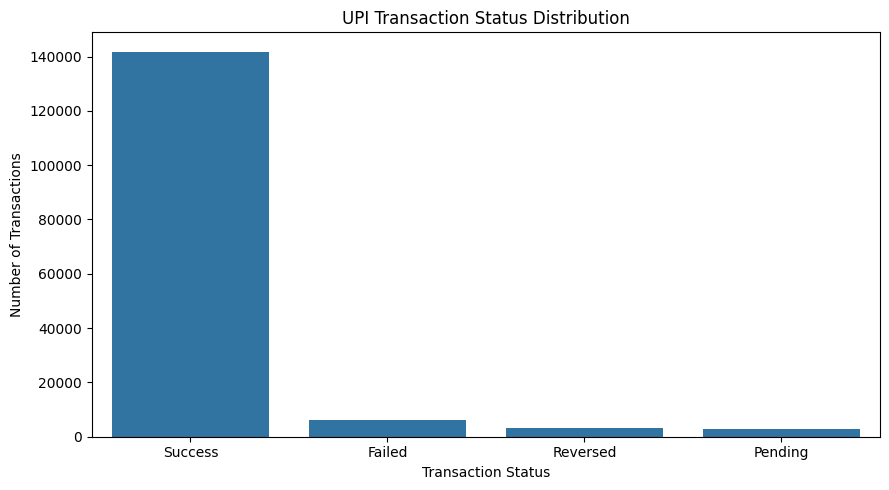

In [31]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(9, 5))

sns.countplot(
    data=upi_df,
    x="transaction_status",
    order=["Success", "Failed", "Reversed", "Pending"]
)

plt.title("UPI Transaction Status Distribution")
plt.xlabel("Transaction Status")
plt.ylabel("Number of Transactions")
plt.tight_layout()
plt.show()

In [32]:
print(df.columns.tolist())

['transaction_id', 'customer_id', 'transaction_date', 'transaction_time', 'account_type', 'transaction_type', 'transaction_amount', 'transaction_direction', 'account_balance', 'merchant_category', 'state', 'credit_score', 'has_loan', 'loan_type', 'emi_amount', 'transaction_status', 'channel', 'kyc_status', 'is_fraud', 'transaction_hour']


In [33]:
upi_amount = upi_df["transaction_amount"]

print("Total UPI Transaction Value:", upi_amount.sum())
print("Average Transaction Value:", upi_amount.mean())
print("Median Transaction Value:", upi_amount.median())
print("Maximum Transaction Value:", upi_amount.max())

Total UPI Transaction Value: 209238290.51
Average Transaction Value: 1358.8137266374865
Median Transaction Value: 657.65
Maximum Transaction Value: 118082.51


In [34]:
import os

os.makedirs("../reports", exist_ok=True)

upi_kpis.to_csv(
    "../reports/upi_performance_kpis.csv",
    index=False
)

## 5. Transaction Amount Distribution Analysis

In [35]:
amount_percentiles = upi_df["transaction_amount"].quantile(
    [0.25, 0.50, 0.75, 0.90, 0.95, 0.99]
)

display(amount_percentiles)

0.25      294.7400
0.50      657.6500
0.75     1484.5775
0.90     3072.1550
0.95     4793.9200
0.99    10828.1775
Name: transaction_amount, dtype: float64

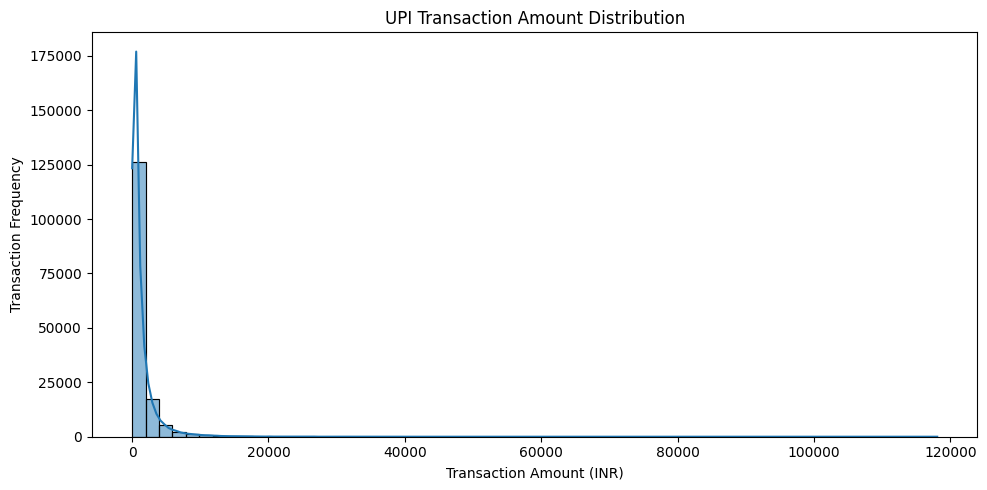

In [36]:
plt.figure(figsize=(10, 5))

sns.histplot(
    data=upi_df,
    x="transaction_amount",
    bins=60,
    kde=True
)

plt.title("UPI Transaction Amount Distribution")
plt.xlabel("Transaction Amount (INR)")
plt.ylabel("Transaction Frequency")

plt.tight_layout()
plt.show()

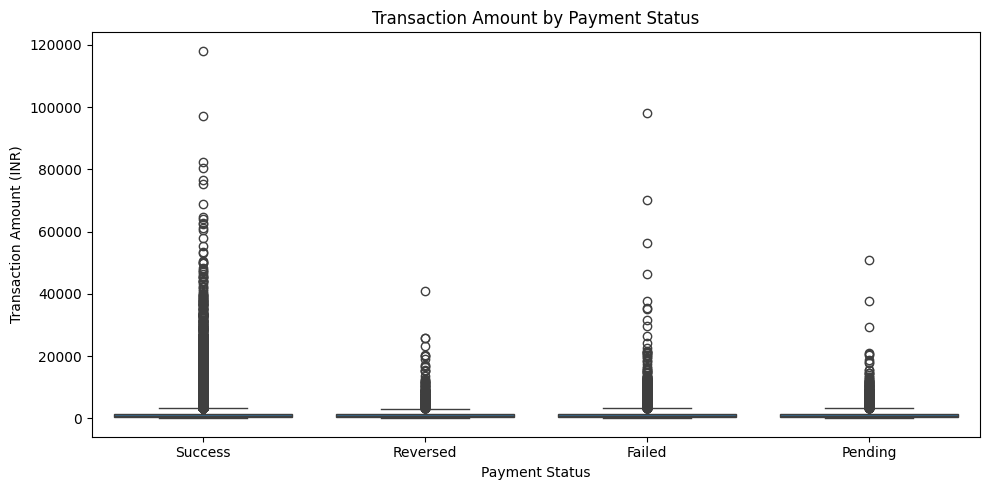

In [37]:
plt.figure(figsize=(10, 5))

sns.boxplot(
    data=upi_df,
    x="transaction_status",
    y="transaction_amount"
)

plt.title("Transaction Amount by Payment Status")
plt.xlabel("Payment Status")
plt.ylabel("Transaction Amount (INR)")

plt.tight_layout()
plt.show()

In [38]:
for col in df.columns:
    print(col)

transaction_id
customer_id
transaction_date
transaction_time
account_type
transaction_type
transaction_amount
transaction_direction
account_balance
merchant_category
state
credit_score
has_loan
loan_type
emi_amount
transaction_status
channel
kyc_status
is_fraud
transaction_hour


## 6. Data Cleaning and Feature Engineering


In [39]:
clean_df = df.copy()

print("Original dataset:", df.shape)
print("Working dataset:", clean_df.shape)

Original dataset: (550000, 20)
Working dataset: (550000, 20)


In [40]:
clean_df.columns = (
    clean_df.columns
    .str.strip()
    .str.lower()
    .str.replace(" ", "_")
)

print(clean_df.columns.tolist())

['transaction_id', 'customer_id', 'transaction_date', 'transaction_time', 'account_type', 'transaction_type', 'transaction_amount', 'transaction_direction', 'account_balance', 'merchant_category', 'state', 'credit_score', 'has_loan', 'loan_type', 'emi_amount', 'transaction_status', 'channel', 'kyc_status', 'is_fraud', 'transaction_hour']


In [41]:
before = len(clean_df)

clean_df = clean_df.drop_duplicates()

after = len(clean_df)

print("Rows before:", before)
print("Rows after:", after)
print("Duplicates removed:", before - after)

Rows before: 550000
Rows after: 550000
Duplicates removed: 0


In [42]:
print(
    "Duplicate transaction IDs:",
    clean_df["transaction_id"].duplicated().sum()
)

Duplicate transaction IDs: 0


In [43]:
missing_report = pd.DataFrame({
    "Missing_Count": clean_df.isnull().sum(),
    "Missing_Percentage": (
        clean_df.isnull().mean() * 100
    ).round(2)
})

display(
    missing_report.sort_values(
        "Missing_Percentage",
        ascending=False
    )
)

,Missing_Count,Missing_Percentage
loan_type,377134,68.57
transaction_id,0,0.00
customer_id,0,0.00
is_fraud,0,0.00
kyc_status,0,0.00
channel,0,0.00
transaction_status,0,0.00
emi_amount,0,0.00
has_loan,0,0.00
credit_score,0,0.00


In [44]:
clean_df["transaction_date"] = pd.to_datetime(
    clean_df["transaction_date"],
    errors="coerce"
)

clean_df["transaction_time"] = pd.to_datetime(
    clean_df["transaction_time"].astype(str),
    format="%H:%M",
    errors="coerce"
).dt.time

In [45]:
clean_df["transaction_datetime"] = pd.to_datetime(
    clean_df["transaction_date"].dt.strftime("%Y-%m-%d")
    + " "
    + clean_df["transaction_time"].astype(str),
    errors="coerce"
)

In [46]:
clean_df["transaction_year"] = (
    clean_df["transaction_datetime"].dt.year
)

clean_df["transaction_month"] = (
    clean_df["transaction_datetime"].dt.month
)

clean_df["month_name"] = (
    clean_df["transaction_datetime"].dt.month_name()
)

clean_df["day_name"] = (
    clean_df["transaction_datetime"].dt.day_name()
)

clean_df["transaction_hour_derived"] = (
    clean_df["transaction_datetime"].dt.hour
)

clean_df["is_weekend"] = (
    clean_df["transaction_datetime"].dt.dayofweek >= 5
).astype("Int64")

In [47]:
upi_clean = clean_df[
    clean_df["transaction_type"]
    .astype("string")
    .str.strip()
    .str.upper()
    == "UPI"
].copy()

print("UPI transactions:", len(upi_clean))

UPI transactions: 153986


## 7. Customer Behaviour Analysis

In [49]:
customer_features = (
    clean_df.dropna(
        subset=["customer_id", "transaction_datetime"]
    )
    .groupby("customer_id")
    .agg(
        total_transactions=("transaction_id", "nunique"),
        total_transaction_value=("transaction_amount", "sum"),
        average_transaction_value=("transaction_amount", "mean"),
        first_transaction=("transaction_datetime", "min"),
        last_transaction=("transaction_datetime", "max"),
        successful_transactions=("is_success", "sum"),
        failed_transactions=("is_failed", "sum")
    )
    .reset_index()
)

display(customer_features.head())

KeyError: "Column(s) ['is_failed', 'is_success'] do not exist"

In [50]:
# Check all column names in clean_df
print(clean_df.columns.tolist())

['transaction_id', 'customer_id', 'transaction_date', 'transaction_time', 'account_type', 'transaction_type', 'transaction_amount', 'transaction_direction', 'account_balance', 'merchant_category', 'state', 'credit_score', 'has_loan', 'loan_type', 'emi_amount', 'transaction_status', 'channel', 'kyc_status', 'is_fraud', 'transaction_hour', 'transaction_datetime', 'transaction_year', 'transaction_month', 'month_name', 'day_name', 'transaction_hour_derived', 'is_weekend']


In [51]:
clean_df.columns = clean_df.columns.str.strip()

In [52]:
required_columns = [
    "customer_id",
    "transaction_datetime"
]

for col in required_columns:
    print(col, ":", col in clean_df.columns)

customer_id : True
transaction_datetime : True


In [53]:
customer_features = (
    clean_df.dropna(
        subset=["customer_id", "transaction_datetime"]
    )
    .groupby("customer_id")
    .agg(
        total_transactions=("transaction_id", "nunique"),
        total_transaction_value=("transaction_amount", "sum"),
        average_transaction_value=("transaction_amount", "mean"),
        first_transaction=("transaction_datetime", "min"),
        last_transaction=("transaction_datetime", "max"),
        successful_transactions=("is_success", "sum"),
        failed_transactions=("is_failed", "sum")
    )
    .reset_index()
)

display(customer_features.head())

KeyError: "Column(s) ['is_failed', 'is_success'] do not exist"

In [54]:
print("Available columns:")
print(clean_df.columns.tolist())

print("\nRequired columns:")
print([
    "customer_id",
    "transaction_datetime",
    "transaction_id",
    "transaction_amount",
    "is_success",
    "is_failed"
])

Available columns:
['transaction_id', 'customer_id', 'transaction_date', 'transaction_time', 'account_type', 'transaction_type', 'transaction_amount', 'transaction_direction', 'account_balance', 'merchant_category', 'state', 'credit_score', 'has_loan', 'loan_type', 'emi_amount', 'transaction_status', 'channel', 'kyc_status', 'is_fraud', 'transaction_hour', 'transaction_datetime', 'transaction_year', 'transaction_month', 'month_name', 'day_name', 'transaction_hour_derived', 'is_weekend']

Required columns:
['customer_id', 'transaction_datetime', 'transaction_id', 'transaction_amount', 'is_success', 'is_failed']


In [55]:
clean_df["transaction_date"] = pd.to_datetime(
    clean_df["transaction_date"],
    errors="coerce"
)

clean_df["transaction_datetime"] = pd.to_datetime(
    clean_df["transaction_date"].dt.strftime("%Y-%m-%d")
    + " "
    + clean_df["transaction_time"].astype(str),
    errors="coerce"
)

print(clean_df["transaction_datetime"].head())

0   2019-01-01 15:28:00
1   2019-01-01 03:00:00
2   2019-01-01 18:03:00
3   2019-01-01 08:03:00
4   2019-01-01 14:23:00
Name: transaction_datetime, dtype: datetime64[ns]


In [56]:
clean_df["is_success"] = (
    clean_df["transaction_status"] == "Success"
).astype(int)

clean_df["is_failed"] = (
    clean_df["transaction_status"] == "Failed"
).astype(int)

In [57]:
customer_features = (
    clean_df.dropna(
        subset=["customer_id", "transaction_datetime"]
    )
    .groupby("customer_id")
    .agg(
        total_transactions=("transaction_id", "nunique"),
        total_transaction_value=("transaction_amount", "sum"),
        average_transaction_value=("transaction_amount", "mean"),
        first_transaction=("transaction_datetime", "min"),
        last_transaction=("transaction_datetime", "max"),
        successful_transactions=("is_success", "sum"),
        failed_transactions=("is_failed", "sum")
    )
    .reset_index()
)

display(customer_features.head())

,customer_id,total_transactions,total_transaction_value,average_transaction_value,first_transaction,last_transaction,successful_transactions,failed_transactions
0,CUST000001,5,3276.58,655.316000,2020-03-30 14:34:00,2023-12-16 22:54:00,5,0
1,CUST000002,7,152940.68,21848.668571,2019-07-19 04:29:00,2021-12-05 13:43:00,7,0
2,CUST000003,8,119842.16,14980.270000,2019-01-28 18:33:00,2023-07-21 19:33:00,8,0
3,CUST000004,8,123820.11,15477.513750,2019-10-14 09:18:00,2023-02-01 12:12:00,7,1
4,CUST000005,5,66083.27,13216.654000,2020-09-24 22:47:00,2023-09-09 03:34:00,4,0


In [58]:
print("Total customers:", len(customer_features))
print("Unique customer IDs:", customer_features["customer_id"].nunique())

print("\nCustomer feature summary:")
display(customer_features.describe())

Total customers: 79916
Unique customer IDs: 79916

Customer feature summary:


,total_transactions,total_transaction_value,average_transaction_value,first_transaction,last_transaction,successful_transactions,failed_transactions
count,79916.000000,7.991600e+04,7.991600e+04,79916,79916,79916.000000,79916.000000
mean,6.882226,2.058274e+05,2.994320e+04,2019-09-21 18:05:31.184743936,2023-04-12 07:30:38.215876864,6.334739,0.274100
min,1.000000,2.495000e+01,2.495000e+01,2019-01-01 00:01:00,2019-01-07 19:06:00,0.000000,0.000000
25%,5.000000,2.545999e+04,4.139261e+03,2019-03-18 22:52:00,2022-12-28 15:20:45,5.000000,0.000000
50%,7.000000,7.980920e+04,1.167549e+04,2019-07-03 21:54:30,2023-07-01 18:58:30,6.000000,0.000000
75%,9.000000,2.365809e+05,3.302843e+04,2020-01-02 05:52:00,2023-10-17 03:45:30,8.000000,0.000000
max,20.000000,1.016993e+07,2.000551e+06,2023-12-30 19:35:00,2024-01-01 23:58:00,20.000000,5.000000
std,2.604967,3.751160e+05,5.813554e+04,NaN,NaN,2.505329,0.523906


In [59]:
successful_df = clean_df[
    (clean_df["transaction_status"] == "Success") &
    (clean_df["customer_id"].notna()) &
    (clean_df["transaction_datetime"].notna()) &
    (clean_df["transaction_amount"].notna())
].copy()

print("Successful transactions:", len(successful_df))

Successful transactions: 506247


In [60]:
snapshot_date = (
    clean_df["transaction_datetime"].max()
    + pd.Timedelta(days=1)
)

rfm = successful_df.groupby("customer_id").agg(
    Recency=("transaction_datetime",
             lambda x: (snapshot_date - x.max()).days),

    Frequency=("transaction_id", "nunique"),

    Monetary=("transaction_amount", "sum")
).reset_index()

display(rfm.head())

,customer_id,Recency,Frequency,Monetary
0,CUST000001,17,5,3276.58
1,CUST000002,758,7,152940.68
2,CUST000003,165,8,119842.16
3,CUST000004,335,7,123539.78
4,CUST000005,115,4,44564.75


In [61]:
rfm["R_Score"] = pd.qcut(
    rfm["Recency"].rank(method="first"),
    5,
    labels=[5, 4, 3, 2, 1]
).astype(int)

rfm["F_Score"] = pd.qcut(
    rfm["Frequency"].rank(method="first"),
    5,
    labels=[1, 2, 3, 4, 5]
).astype(int)

rfm["M_Score"] = pd.qcut(
    rfm["Monetary"].rank(method="first"),
    5,
    labels=[1, 2, 3, 4, 5]
).astype(int)

rfm["RFM_Score"] = (
    rfm["R_Score"].astype(str) +
    rfm["F_Score"].astype(str) +
    rfm["M_Score"].astype(str)
)

display(rfm.head(10))

,customer_id,Recency,Frequency,Monetary,R_Score,F_Score,M_Score,RFM_Score
0,CUST000001,17,5,3276.58,5,2,1,521
1,CUST000002,758,7,152940.68,1,3,4,134
2,CUST000003,165,8,119842.16,3,4,4,344
3,CUST000004,335,7,123539.78,2,3,4,234
4,CUST000005,115,4,44564.75,4,1,3,413
5,CUST000006,316,11,203569.82,2,5,4,254
6,CUST000007,877,4,33662.12,1,1,2,112
7,CUST000008,810,3,20088.52,1,1,2,112
8,CUST000009,187,8,612906.06,3,4,5,345
9,CUST000010,22,5,105588.79,5,2,3,523


In [62]:
def segment_customer(row):

    if row["R_Score"] >= 4 and row["F_Score"] >= 4:
        return "Loyal Customers"

    elif row["R_Score"] >= 4 and row["M_Score"] >= 4:
        return "High Value Customers"

    elif row["R_Score"] <= 2 and row["F_Score"] >= 3:
        return "At Risk Customers"

    elif row["R_Score"] == 1:
        return "Inactive Customers"

    else:
        return "Regular Customers"


rfm["Customer_Segment"] = rfm.apply(
    segment_customer,
    axis=1
)

display(rfm.head(10))

,customer_id,Recency,Frequency,Monetary,R_Score,F_Score,M_Score,RFM_Score,Customer_Segment
0,CUST000001,17,5,3276.58,5,2,1,521,Regular Customers
1,CUST000002,758,7,152940.68,1,3,4,134,At Risk Customers
2,CUST000003,165,8,119842.16,3,4,4,344,Regular Customers
3,CUST000004,335,7,123539.78,2,3,4,234,At Risk Customers
4,CUST000005,115,4,44564.75,4,1,3,413,Regular Customers
5,CUST000006,316,11,203569.82,2,5,4,254,At Risk Customers
6,CUST000007,877,4,33662.12,1,1,2,112,Inactive Customers
7,CUST000008,810,3,20088.52,1,1,2,112,Inactive Customers
8,CUST000009,187,8,612906.06,3,4,5,345,Regular Customers
9,CUST000010,22,5,105588.79,5,2,3,523,Regular Customers


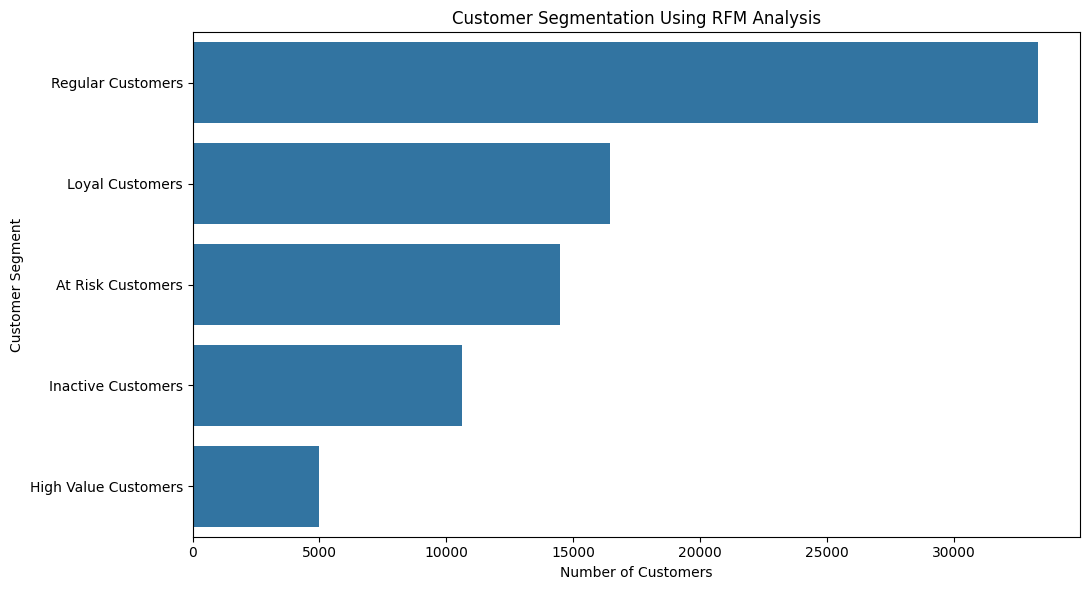

In [63]:
plt.figure(figsize=(11, 6))

sns.countplot(
    data=rfm,
    y="Customer_Segment",
    order=rfm["Customer_Segment"].value_counts().index
)

plt.title("Customer Segmentation Using RFM Analysis")
plt.xlabel("Number of Customers")
plt.ylabel("Customer Segment")
plt.tight_layout()
plt.show()

In [64]:
rfm.to_csv(
    "../data/processed/customer_rfm_segments.csv",
    index=False
)

print("RFM segmentation exported successfully!")

RFM segmentation exported successfully!


In [65]:
print("Total RFM customers:", len(rfm))

print("\nCustomer segment distribution:")

display(
    rfm["Customer_Segment"].value_counts()
)

print("\nRFM summary:")

display(
    rfm[["Recency", "Frequency", "Monetary"]].describe()
)

Total RFM customers: 79867

Customer segment distribution:


Customer_Segment
Regular Customers       33320
Loyal Customers         16440
At Risk Customers       14506
Inactive Customers      10630
High Value Customers     4971
Name: count, dtype: int64


RFM summary:


,Recency,Frequency,Monetary
count,79867.000000,79867.000000,7.986700e+04
mean,287.240487,6.338625,1.889616e+05
std,279.933076,2.501178,3.576186e+05
min,1.000000,1.000000,1.873000e+01
25%,84.000000,5.000000,2.118731e+04
50%,200.000000,6.000000,6.780918e+04
75%,402.000000,8.000000,2.122954e+05
max,1825.000000,20.000000,1.016993e+07


## 9. Customer Cohort and Retention Analysis

In [66]:
cohort_df = successful_df[
    ["customer_id", "transaction_datetime"]
].copy()

cohort_df["transaction_month"] = (
    cohort_df["transaction_datetime"].dt.to_period("M")
)

print("Total records:", len(cohort_df))
print("Unique customers:", cohort_df["customer_id"].nunique())

Total records: 506247
Unique customers: 79867


In [67]:
cohort_df["cohort_month"] = (
    cohort_df.groupby("customer_id")["transaction_month"]
    .transform("min")
)

display(cohort_df.head(10))

,customer_id,transaction_datetime,transaction_month,cohort_month
0,CUST015796,2019-01-01 15:28:00,2019-01,2019-01
1,CUST000861,2019-01-01 03:00:00,2019-01,2019-01
2,CUST076821,2019-01-01 18:03:00,2019-01,2019-01
3,CUST054887,2019-01-01 08:03:00,2019-01,2019-01
4,CUST006266,2019-01-01 14:23:00,2019-01,2019-01
6,CUST044132,2019-01-01 06:27:00,2019-01,2019-01
7,CUST060264,2019-01-01 23:40:00,2019-01,2019-01
8,CUST016024,2019-01-01 20:25:00,2019-01,2019-01
9,CUST041091,2019-01-01 22:15:00,2019-01,2019-01
10,CUST067222,2019-01-01 08:50:00,2019-01,2019-01


In [68]:
cohort_df["cohort_index"] = (
    (cohort_df["transaction_month"].dt.year -
     cohort_df["cohort_month"].dt.year) * 12
    +
    (cohort_df["transaction_month"].dt.month -
     cohort_df["cohort_month"].dt.month)
)

display(cohort_df.head())

,customer_id,transaction_datetime,transaction_month,cohort_month,cohort_index
0,CUST015796,2019-01-01 15:28:00,2019-01,2019-01,0
1,CUST000861,2019-01-01 03:00:00,2019-01,2019-01,0
2,CUST076821,2019-01-01 18:03:00,2019-01,2019-01,0
3,CUST054887,2019-01-01 08:03:00,2019-01,2019-01,0
4,CUST006266,2019-01-01 14:23:00,2019-01,2019-01,0


In [69]:
cohort_data = (
    cohort_df.groupby(
        ["cohort_month", "cohort_index"]
    )["customer_id"]
    .nunique()
    .reset_index()
)

cohort_counts = cohort_data.pivot(
    index="cohort_month",
    columns="cohort_index",
    values="customer_id"
)

display(cohort_counts.head(10))

cohort_index,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20,21,22,23,24,25,26,27,28,29,30,31,32,33,34,35,36,37,38,39,40,41,42,43,44,45,46,47,48,49,50,51,52,53,54,55,56,57,58,59,60
cohort_month,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
2019-01,8171.0,765.0,839.0,792.0,836.0,837.0,844.0,827.0,807.0,847.0,841.0,839.0,825.0,735.0,817.0,820.0,824.0,806.0,803.0,874.0,793.0,820.0,770.0,767.0,822.0,739.0,805.0,801.0,838.0,840.0,803.0,786.0,812.0,853.0,781.0,847.0,795.0,741.0,818.0,804.0,805.0,804.0,821.0,823.0,811.0,856.0,846.0,844.0,855.0,722.0,807.0,789.0,842.0,781.0,750.0,825.0,832.0,801.0,814.0,817.0,28.0
2019-02,6420.0,679.0,655.0,661.0,632.0,629.0,683.0,616.0,682.0,630.0,623.0,665.0,608.0,690.0,645.0,654.0,656.0,641.0,676.0,636.0,627.0,641.0,633.0,654.0,607.0,664.0,663.0,666.0,612.0,652.0,660.0,642.0,638.0,618.0,663.0,658.0,552.0,661.0,653.0,678.0,675.0,693.0,663.0,642.0,636.0,651.0,620.0,623.0,576.0,646.0,655.0,634.0,651.0,683.0,627.0,627.0,676.0,613.0,635.0,21.0,NaN
2019-03,6564.0,620.0,678.0,622.0,661.0,713.0,616.0,698.0,663.0,674.0,666.0,646.0,667.0,588.0,677.0,668.0,683.0,689.0,620.0,700.0,651.0,638.0,665.0,558.0,647.0,637.0,694.0,644.0,636.0,648.0,638.0,660.0,650.0,713.0,657.0,609.0,650.0,617.0,706.0,613.0,665.0,696.0,629.0,635.0,645.0,651.0,680.0,621.0,621.0,648.0,724.0,621.0,667.0,671.0,664.0,674.0,652.0,686.0,27.0,NaN,NaN
2019-04,5764.0,575.0,529.0,615.0,592.0,547.0,590.0,552.0,571.0,623.0,546.0,573.0,598.0,572.0,530.0,545.0,605.0,555.0,533.0,571.0,594.0,616.0,525.0,592.0,578.0,599.0,585.0,564.0,596.0,582.0,587.0,571.0,582.0,610.0,569.0,632.0,546.0,577.0,553.0,568.0,591.0,576.0,564.0,563.0,591.0,545.0,490.0,571.0,574.0,583.0,592.0,598.0,599.0,592.0,619.0,567.0,562.0,19.0,NaN,NaN,NaN
2019-05,5469.0,538.0,551.0,566.0,543.0,577.0,543.0,550.0,579.0,527.0,579.0,518.0,569.0,523.0,550.0,554.0,556.0,549.0,556.0,569.0,563.0,519.0,555.0,536.0,555.0,545.0,540.0,552.0,558.0,564.0,530.0,546.0,551.0,525.0,605.0,544.0,545.0,535.0,539.0,541.0,532.0,563.0,503.0,540.0,559.0,518.0,557.0,583.0,551.0,533.0,592.0,578.0,539.0,585.0,532.0,540.0,16.0,NaN,NaN,NaN,NaN
2019-06,4757.0,492.0,542.0,452.0,501.0,444.0,505.0,493.0,455.0,459.0,493.0,464.0,499.0,491.0,511.0,490.0,479.0,485.0,485.0,496.0,474.0,494.0,452.0,515.0,454.0,478.0,477.0,484.0,523.0,455.0,486.0,474.0,429.0,471.0,467.0,488.0,500.0,460.0,490.0,463.0,478.0,532.0,498.0,482.0,453.0,500.0,488.0,437.0,460.0,468.0,495.0,469.0,471.0,459.0,473.0,13.0,NaN,NaN,NaN,NaN,NaN
2019-07,4413.0,442.0,435.0,486.0,403.0,426.0,436.0,426.0,438.0,469.0,436.0,414.0,465.0,457.0,469.0,444.0,430.0,441.0,492.0,398.0,474.0,439.0,415.0,439.0,448.0,422.0,440.0,463.0,454.0,430.0,467.0,422.0,440.0,425.0,477.0,429.0,462.0,461.0,438.0,452.0,460.0,431.0,464.0,427.0,445.0,423.0,460.0,463.0,459.0,465.0,438.0,429.0,434.0,422.0,15.0,NaN,NaN,NaN,NaN,NaN,NaN
2019-08,3953.0,381.0,390.0,385.0,401.0,401.0,408.0,375.0,371.0,418.0,381.0,406.0,395.0,376.0,375.0,399.0,423.0,412.0,354.0,394.0,384.0,365.0,398.0,387.0,439.0,387.0,394.0,404.0,397.0,405.0,383.0,412.0,405.0,413.0,359.0,411.0,391.0,407.0,422.0,401.0,384.0,416.0,340.0,379.0,369.0,383.0,372.0,413.0,375.0,388.0,383.0,390.0,422.0,20.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2019-09,3383.0,375.0,316.0,349.0,368.0,340.0,335.0,314.0,370.0,357.0,366.0,354.0,345.0,318.0,303.0,356.0,332.0,343.0,330.0,313.0,339.0,346.0,363.0,330.0,320.0,342.0,338.0,361.0,354.0,300.0,345.0,346.0,344.0,350.0,325.0,332.0,368.0,347.0,364.0,346.0,358.0,313.0,347.0,325.0,339.0,339.0,395.0,376.0,354.0,358.0,327.0,334.0,11.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [70]:
plt.figure(figsize=(16, 9))

sns.heatmap(
    retention,
    annot=True,
    fmt=".0f",
    cmap="YlGnBu",
    linewidths=0.5,
    vmin=0,
    vmax=100
)

plt.title(
    "Customer Cohort Retention Analysis",
    fontsize=16
)

plt.xlabel("Months Since First Transaction")
plt.ylabel("Customer Acquisition Cohort")

plt.tight_layout()
plt.show()

NameError: name 'retention' is not defined

<Figure size 1600x900 with 0 Axes>

In [71]:
# Prepare successful transaction data

cohort_df = successful_df[
    ["customer_id", "transaction_datetime"]
].dropna().copy()

# Convert transaction dates into monthly periods

cohort_df["transaction_month"] = (
    cohort_df["transaction_datetime"].dt.to_period("M")
)

# Identify first transaction month for each customer

cohort_df["cohort_month"] = (
    cohort_df.groupby("customer_id")["transaction_month"]
    .transform("min")
)

# Calculate cohort index

cohort_df["cohort_index"] = (
    (cohort_df["transaction_month"].dt.year -
     cohort_df["cohort_month"].dt.year) * 12
    +
    (cohort_df["transaction_month"].dt.month -
     cohort_df["cohort_month"].dt.month)
)

# Calculate unique active customers

cohort_data = (
    cohort_df.groupby(
        ["cohort_month", "cohort_index"]
    )["customer_id"]
    .nunique()
    .reset_index()
)

# Create cohort matrix

cohort_counts = cohort_data.pivot(
    index="cohort_month",
    columns="cohort_index",
    values="customer_id"
)

# Calculate retention percentage

cohort_sizes = cohort_counts.iloc[:, 0]

retention = (
    cohort_counts.divide(cohort_sizes, axis=0) * 100
).round(2)

display(retention.head(10))

cohort_index,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20,21,22,23,24,25,26,27,28,29,30,31,32,33,34,35,36,37,38,39,40,41,42,43,44,45,46,47,48,49,50,51,52,53,54,55,56,57,58,59,60
cohort_month,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
2019-01,100.0,9.36,10.27,9.69,10.23,10.24,10.33,10.12,9.88,10.37,10.29,10.27,10.10,9.00,10.00,10.04,10.08,9.86,9.83,10.70,9.71,10.04,9.42,9.39,10.06,9.04,9.85,9.80,10.26,10.28,9.83,9.62,9.94,10.44,9.56,10.37,9.73,9.07,10.01,9.84,9.85,9.84,10.05,10.07,9.93,10.48,10.35,10.33,10.46,8.84,9.88,9.66,10.30,9.56,9.18,10.10,10.18,9.80,9.96,10.00,0.34
2019-02,100.0,10.58,10.20,10.30,9.84,9.80,10.64,9.60,10.62,9.81,9.70,10.36,9.47,10.75,10.05,10.19,10.22,9.98,10.53,9.91,9.77,9.98,9.86,10.19,9.45,10.34,10.33,10.37,9.53,10.16,10.28,10.00,9.94,9.63,10.33,10.25,8.60,10.30,10.17,10.56,10.51,10.79,10.33,10.00,9.91,10.14,9.66,9.70,8.97,10.06,10.20,9.88,10.14,10.64,9.77,9.77,10.53,9.55,9.89,0.33,NaN
2019-03,100.0,9.45,10.33,9.48,10.07,10.86,9.38,10.63,10.10,10.27,10.15,9.84,10.16,8.96,10.31,10.18,10.41,10.50,9.45,10.66,9.92,9.72,10.13,8.50,9.86,9.70,10.57,9.81,9.69,9.87,9.72,10.05,9.90,10.86,10.01,9.28,9.90,9.40,10.76,9.34,10.13,10.60,9.58,9.67,9.83,9.92,10.36,9.46,9.46,9.87,11.03,9.46,10.16,10.22,10.12,10.27,9.93,10.45,0.41,NaN,NaN
2019-04,100.0,9.98,9.18,10.67,10.27,9.49,10.24,9.58,9.91,10.81,9.47,9.94,10.37,9.92,9.20,9.46,10.50,9.63,9.25,9.91,10.31,10.69,9.11,10.27,10.03,10.39,10.15,9.78,10.34,10.10,10.18,9.91,10.10,10.58,9.87,10.96,9.47,10.01,9.59,9.85,10.25,9.99,9.78,9.77,10.25,9.46,8.50,9.91,9.96,10.11,10.27,10.37,10.39,10.27,10.74,9.84,9.75,0.33,NaN,NaN,NaN
2019-05,100.0,9.84,10.07,10.35,9.93,10.55,9.93,10.06,10.59,9.64,10.59,9.47,10.40,9.56,10.06,10.13,10.17,10.04,10.17,10.40,10.29,9.49,10.15,9.80,10.15,9.97,9.87,10.09,10.20,10.31,9.69,9.98,10.07,9.60,11.06,9.95,9.97,9.78,9.86,9.89,9.73,10.29,9.20,9.87,10.22,9.47,10.18,10.66,10.07,9.75,10.82,10.57,9.86,10.70,9.73,9.87,0.29,NaN,NaN,NaN,NaN
2019-06,100.0,10.34,11.39,9.50,10.53,9.33,10.62,10.36,9.56,9.65,10.36,9.75,10.49,10.32,10.74,10.30,10.07,10.20,10.20,10.43,9.96,10.38,9.50,10.83,9.54,10.05,10.03,10.17,10.99,9.56,10.22,9.96,9.02,9.90,9.82,10.26,10.51,9.67,10.30,9.73,10.05,11.18,10.47,10.13,9.52,10.51,10.26,9.19,9.67,9.84,10.41,9.86,9.90,9.65,9.94,0.27,NaN,NaN,NaN,NaN,NaN
2019-07,100.0,10.02,9.86,11.01,9.13,9.65,9.88,9.65,9.93,10.63,9.88,9.38,10.54,10.36,10.63,10.06,9.74,9.99,11.15,9.02,10.74,9.95,9.40,9.95,10.15,9.56,9.97,10.49,10.29,9.74,10.58,9.56,9.97,9.63,10.81,9.72,10.47,10.45,9.93,10.24,10.42,9.77,10.51,9.68,10.08,9.59,10.42,10.49,10.40,10.54,9.93,9.72,9.83,9.56,0.34,NaN,NaN,NaN,NaN,NaN,NaN
2019-08,100.0,9.64,9.87,9.74,10.14,10.14,10.32,9.49,9.39,10.57,9.64,10.27,9.99,9.51,9.49,10.09,10.70,10.42,8.96,9.97,9.71,9.23,10.07,9.79,11.11,9.79,9.97,10.22,10.04,10.25,9.69,10.42,10.25,10.45,9.08,10.40,9.89,10.30,10.68,10.14,9.71,10.52,8.60,9.59,9.33,9.69,9.41,10.45,9.49,9.82,9.69,9.87,10.68,0.51,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2019-09,100.0,11.08,9.34,10.32,10.88,10.05,9.90,9.28,10.94,10.55,10.82,10.46,10.20,9.40,8.96,10.52,9.81,10.14,9.75,9.25,10.02,10.23,10.73,9.75,9.46,10.11,9.99,10.67,10.46,8.87,10.20,10.23,10.17,10.35,9.61,9.81,10.88,10.26,10.76,10.23,10.58,9.25,10.26,9.61,10.02,10.02,11.68,11.11,10.46,10.58,9.67,9.87,0.33,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


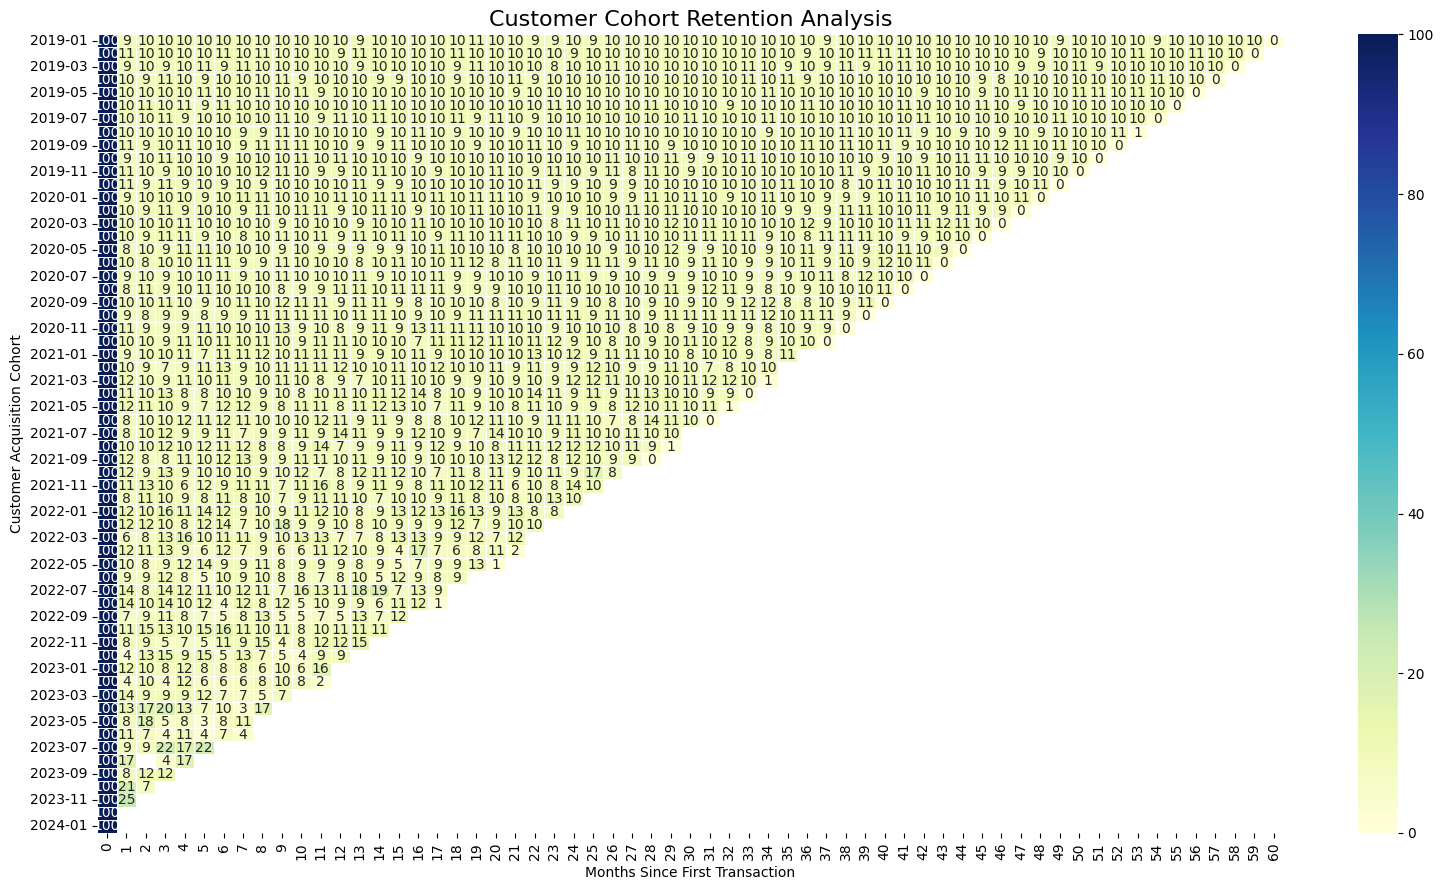

In [72]:
plt.figure(figsize=(16, 9))

sns.heatmap(
    retention,
    annot=True,
    fmt=".0f",
    cmap="YlGnBu",
    linewidths=0.5,
    vmin=0,
    vmax=100
)

plt.title("Customer Cohort Retention Analysis", fontsize=16)
plt.xlabel("Months Since First Transaction")
plt.ylabel("Customer Acquisition Cohort")

plt.tight_layout()
plt.show()

In [73]:
cohort_counts.to_csv(
    "../data/processed/cohort_customer_counts.csv"
)

retention.to_csv(
    "../data/processed/cohort_retention_matrix.csv"
)

print("Cohort analysis completed successfully!")

Cohort analysis completed successfully!


## 10. D7 and D30 Customer Retention


In [74]:
# Dataset observation end date

observation_end = successful_df[
    "transaction_datetime"
].max()

# First successful transaction per customer

first_dates = (
    successful_df.groupby("customer_id")
    ["transaction_datetime"]
    .min()
)

# Calculate retention eligibility

eligible_7d = first_dates[
    first_dates <= observation_end - pd.Timedelta(days=7)
].index

eligible_30d = first_dates[
    first_dates <= observation_end - pd.Timedelta(days=30)
].index

# Find repeat successful transactions

repeat_transactions = successful_df.merge(
    first_dates.rename("first_transaction"),
    on="customer_id"
)

repeat_transactions["days_since_first"] = (
    repeat_transactions["transaction_datetime"]
    - repeat_transactions["first_transaction"]
).dt.days

repeat_transactions = repeat_transactions[
    repeat_transactions["days_since_first"] > 0
]

# Calculate retention

retained_7d = (
    repeat_transactions[
        repeat_transactions["days_since_first"] <= 7
    ]["customer_id"].nunique()
)

retained_30d = (
    repeat_transactions[
        repeat_transactions["days_since_first"] <= 30
    ]["customer_id"].nunique()
)

d7_rate = retained_7d / len(eligible_7d) * 100
d30_rate = retained_30d / len(eligible_30d) * 100

print("Eligible D7 customers:", len(eligible_7d))
print("D7 retained customers:", retained_7d)
print("D7 retention:", round(d7_rate, 2), "%")

print("\nEligible D30 customers:", len(eligible_30d))
print("D30 retained customers:", retained_30d)
print("D30 retention:", round(d30_rate, 2), "%")

Eligible D7 customers: 79859
D7 retained customers: 1903
D7 retention: 2.38 %

Eligible D30 customers: 79846
D30 retained customers: 7869
D30 retention: 9.86 %


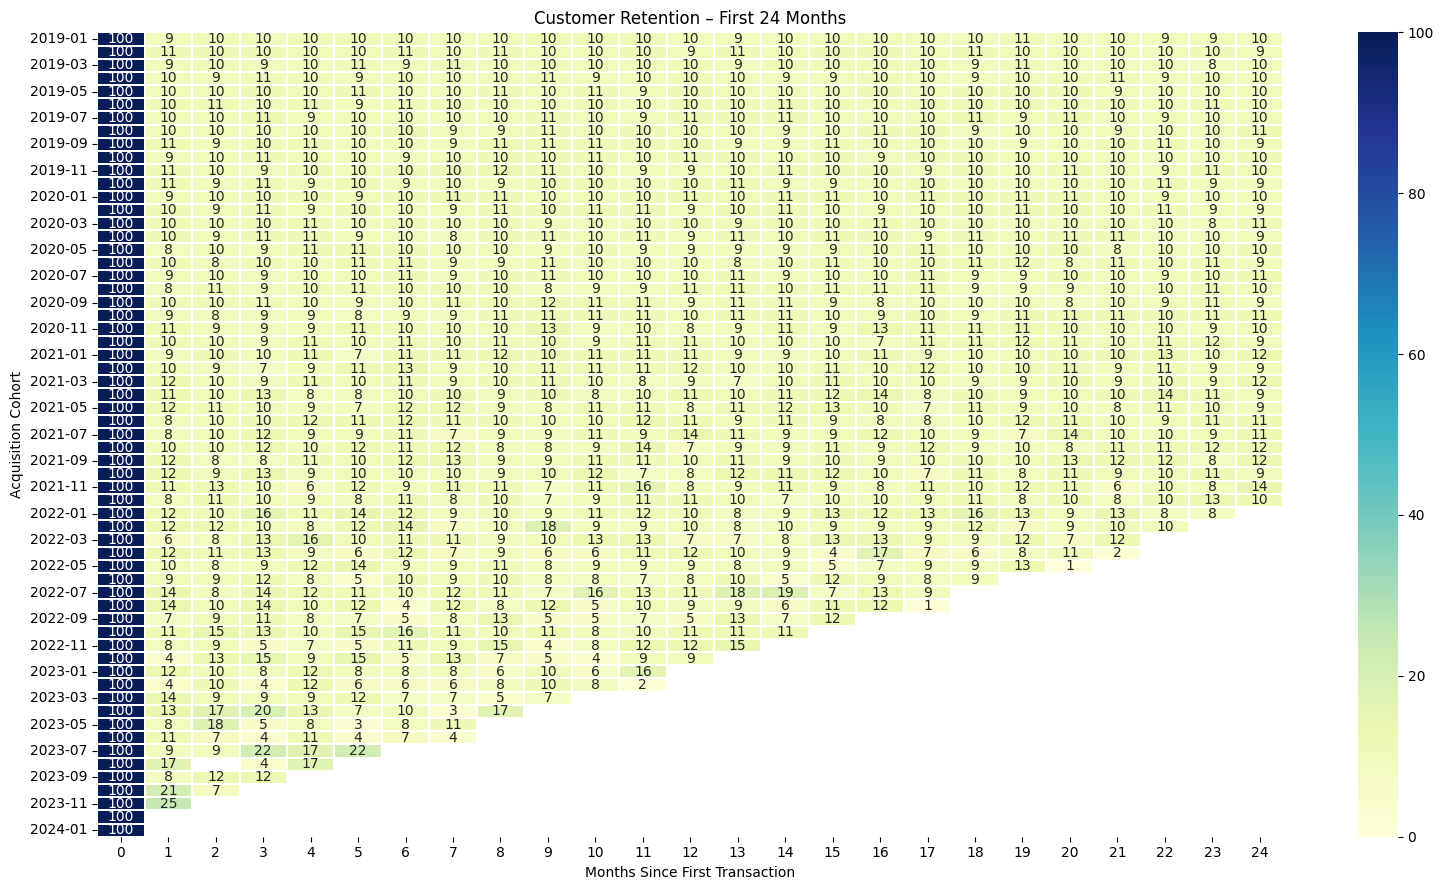

In [75]:
plt.figure(figsize=(16, 9))

sns.heatmap(
    retention.iloc[:, :25],
    cmap="YlGnBu",
    annot=True,
    fmt=".0f",
    vmin=0,
    vmax=100,
    linewidths=0.3
)

plt.title("Customer Retention – First 24 Months")
plt.xlabel("Months Since First Transaction")
plt.ylabel("Acquisition Cohort")

plt.tight_layout()
plt.show()